# Flagged samples: glitches and gaps

`DetectorData.flags` marks samples that must not enter the maps: glitches
(cosmic rays), gaps, data taken during a manoeuvre, ... Flagged samples are
not simply dropped, since $N^{-1}$ is applied with FFTs on contiguous
chunks. Their TOD is never used (it may be NaN), and two
`GLSParameters` choose what happens to them:

- `flag_method="marginalize"` (default): one unknown per flagged sample,
  fitted together with the maps and discarded. This is the exact GLS
  solution without the flagged samples (their noise correlations with the
  other samples are kept); it costs ~70 bytes per flagged sample, local to
  the process that holds it.
- `flag_method="offset"`: the flagged samples are set to 0 and each run of
  them gets one offset. No bias, nearly optimal, no memory.
- `split_gap_s` (default 300 s): runs at least this long split the chunk and
  are dropped, so that long gaps do not slow down the PCG; the noise
  correlations across them are neglected. `inf` never splits, 0 splits at
  every run.

Here: 4 detectors without litebird_sim, sky + 1/f noise ($f_\text{knee}$ =
50 mHz), 50 glitches per detector flagged for 10 s each and a one-hour gap
filled with NaN.

In [1]:
import healpy as hp
import matplotlib.pyplot as plt
import numpy as np
from pysanepic import DetectorData, GLSParameters, OneOverFNoise, Pointing, make_maps, one_over_f_weights

nside, fs, n = 32, 10.0, 1_728_000  # two days at 10 Hz per detector
net, fknee, alpha, fmin = 50.0, 0.05, 1.0, 1e-4
sigma = net * np.sqrt(fs) * 1e-6
rng = np.random.default_rng(1)
sky = rng.normal(0, 30e-6, (3, 12 * nside**2))  # a white-noise sky, in K


def scan(n, rng):
    """Spinning scan in Galactic coordinates covering most of the sky."""
    t = np.arange(n) / fs
    lam = 2 * np.pi * t / (n / fs) + rng.uniform(0, 2 * np.pi)
    spin = 2 * np.pi * t / 60.0
    a = np.array([np.cos(lam), np.sin(lam), np.zeros(n)])
    z = np.array([np.zeros(n), np.zeros(n), np.ones(n)])
    e2 = np.cross(a.T, z.T).T
    b = np.cos(1.3) * a + np.sin(1.3) * (np.cos(spin) * z + np.sin(spin) * e2)
    return np.arccos(np.clip(b[2], -1, 1)), np.arctan2(b[1], b[0]) % (2 * np.pi), (spin + lam) % (2 * np.pi)


def one_over_f(n, chunk, rng):
    """1/f noise with the toast spectrum, generated independently per chunk."""
    out = np.empty(n)
    for a in range(0, n, chunk):
        m = min(chunk, n - a)
        w = one_over_f_weights(m, fs, sigma, fknee, alpha, fmin)
        out[a : a + m] = np.fft.irfft(np.fft.rfft(rng.normal(size=m)) / np.sqrt(w), n=m)
    return out


chunk = int(86400 * fs)
clean, glitchy, flags = [], [], []
for pol_angle in (0.0, np.pi / 4, np.pi / 8, 3 * np.pi / 8):
    theta, phi, psi = scan(n, rng)
    a = psi + pol_angle
    p = hp.ang2pix(nside, theta, phi)
    tod = sky[0, p] + sky[1, p] * np.cos(2 * a) + sky[2, p] * np.sin(2 * a) + one_over_f(n, chunk, rng)
    # glitches: a jump of 20-200 sigma decaying in ~2 s, flagged for 10 s
    f = np.zeros(n, bool)
    bad = tod.copy()
    for t0 in rng.choice(n - 200, 50, replace=False):
        bad[t0 : t0 + 200] += rng.uniform(20, 200) * sigma * np.exp(-np.arange(200) / (2 * fs))
        f[t0 : t0 + 100] = True
    f[300_000:336_000] = True  # a one-hour gap
    bad[300_000:336_000] = np.nan
    ptg = Pointing(theta=theta, phi=phi, psi=psi, coordinates="G")
    noise = OneOverFNoise(net_ukrts=net, fknee_hz=fknee, alpha=alpha, fmin_hz=fmin)
    common = dict(pointing=ptg, sampling_rate_hz=fs, noise=noise, pol_angle_rad=pol_angle)
    clean.append(DetectorData(tod=tod, **common))
    glitchy.append(DetectorData(tod=np.nan_to_num(bad, nan=0.0), **common))  # without flags: zeros in the gap
    flags.append(DetectorData(tod=bad, flags=f, **common))
print(f"flagged samples: {np.mean([d.flags.mean() for d in flags]):.2%}")

flagged samples: 2.36%


Maps of the same data: without glitches (the reference), with the
glitches and the gap not flagged, and flagged with the different methods.

In [2]:
import dataclasses, time

params = GLSParameters(chunk_s=86400.0, tol=1e-12)
runs = {
    "clean": (clean, {}),
    "not flagged": (glitchy, {}),
    "marginalize, split 300 s (default)": (flags, {}),
    "marginalize, no split": (flags, dict(split_gap_s=np.inf)),
    "offset, split 300 s": (flags, dict(flag_method="offset")),
    "offset, no split": (flags, dict(flag_method="offset", split_gap_s=np.inf)),
    "split every run": (flags, dict(split_gap_s=0.0)),
}
res = {}
for name, (data, kw) in runs.items():
    t0 = time.perf_counter()
    res[name] = r = make_maps(data, nside, coordinates="G", params=dataclasses.replace(params, **kw))
    err = (r.maps - sky)[:, r.maps[1] != hp.UNSEEN] * 1e6
    print(f"{name:35s} {r.iterations:3d} it, {time.perf_counter() - t0:5.1f} s, hits {r.hit_map.sum():8d}, "
          f"rms error I/Q/U {err[0].std():5.2f} / {err[1].std():5.2f} / {err[2].std():5.2f} uK")
seen = res["clean"].maps[1] != hp.UNSEEN

clean                                25 it,   9.3 s, hits  6912000, rms error I/Q/U 12.94 / 15.02 / 15.12 uK


not flagged                          26 it,   5.7 s, hits  6912000, rms error I/Q/U 38.51 / 48.45 / 40.68 uK


marginalize, split 300 s (default)   25 it,   5.7 s, hits  6748642, rms error I/Q/U 13.24 / 15.36 / 15.41 uK


marginalize, no split                71 it,  12.5 s, hits  6748642, rms error I/Q/U 13.24 / 15.36 / 15.41 uK


offset, split 300 s                  25 it,   5.7 s, hits  6748642, rms error I/Q/U 13.24 / 15.36 / 15.41 uK


offset, no split                     25 it,   5.7 s, hits  6748642, rms error I/Q/U 13.24 / 15.36 / 15.41 uK


split every run                      24 it,   5.8 s, hits  6748642, rms error I/Q/U 13.24 / 15.36 / 15.41 uK


Flagged samples are not hits. Not flagging the glitches and the gap
biases the maps (stripes along the scan, from the glitches and from the jump
into the zero-filled gap). With flags the maps are as good as the clean
ones, with slightly more noise since ~2% of the samples are not used. The
methods differ mostly in the iterations: the one-hour gap slows down the
PCG unless it is split.

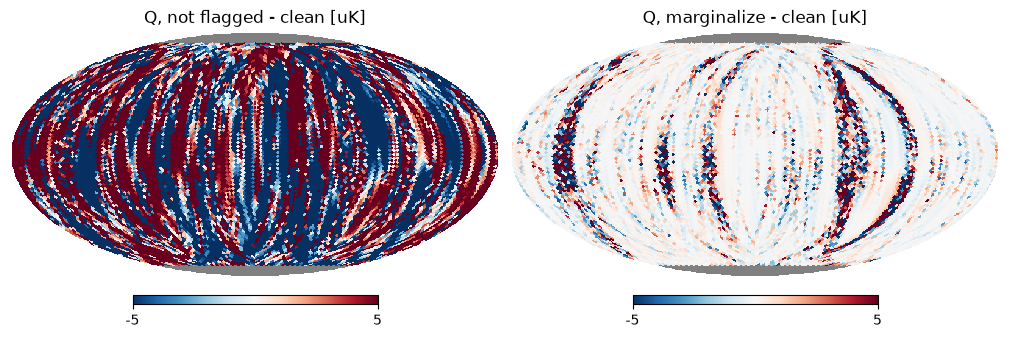

In [3]:
fig = plt.figure(figsize=(10, 3.5))
for i, name in enumerate(("not flagged", "marginalize, split 300 s (default)")):
    d = np.where(seen, (res[name].maps[1] - res["clean"].maps[1]) * 1e6, hp.UNSEEN)
    hp.mollview(d, fig=fig.number, sub=(1, 2, i + 1), title=f"Q, {name.split(',')[0]} - clean [uK]",
                min=-5, max=5, cmap="RdBu_r")
plt.show()